In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
import pingouin as pg

In [2]:
h5="/Users/mollyshallow/Desktop/20251106_LD_gad2cohort1.h5"

In [3]:
## use the below lines to clean up the conditions (will fix this so its not hard coded later)
df=pd.read_hdf(h5, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df['folder_path'].astype('str')))
df['filename']=df['filename'].astype('str')

df['capduration']=df['captureT']-df['timetointercept']


fr=200

nandf=cdc(df)
nans=np.where(nandf['captureT']>=300)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=300)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=300)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)


drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test


test_nandf['condition']=test_nandf['condition'].astype(str)


cleaned_df=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]

hue_order=[1,0]
palette=['#2976bb','#929591']

In [4]:
cleaned_df

,filename,folder_path,condition,laser_value,trials_to_drop,dist,cricket_spd,mouse_spd,az,captureT,...,timetoapproach,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,corrected_timetointercept,corrected_capduration,timestamps
2,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-01-27_9-04-10_mouse-3179,1.0,0.0,left_only,"[67.2677641165626, 64.4469888058745, 61.626213...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.44418427153171414, 0.6613783149799111, 0.93...","[82.3063396100603, 79.19856610505266, 76.09079...",NaN,...,18.315,0.102564,0.250000,49.675,9935.0,11.54350,NaN,40.505,NaN,2025-01-27 09:04:10
3,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-01-27_9-18-36_mouse-3179,1.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.39609845100794067, 0.49055878536258324, 0.3...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,...,19.585,0.250000,1.000000,285.480,57096.0,13.05875,NaN,268.820,NaN,2025-01-27 09:18:36
4,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-01-27_9-25-18_mouse-3179,1.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.14650394979807585, 0.1435393953324133, 0.18...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,...,64.740,1.000000,1.000000,65.005,13001.0,11.99600,NaN,61.015,NaN,2025-01-27 09:25:18
5,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-01-27_9-31-54_mouse-3179,1.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.46790578447088127, 0.4314516853623946, 0.42...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",217.470,...,30.045,0.150000,0.333333,124.440,24888.0,10.50700,93.030,114.020,103.450,2025-01-27 09:31:54
6,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-01-27_9-39-06_mouse-3179,1.0,0.0,left_only,"[71.3361589483401, 71.22121061208601, 71.22141...","[0.44743647397644437, 0.49775870078508444, 0.4...","[3.5499242782606855, 3.64627774624085, 3.71758...","[125.73494144457423, 104.79244369087591, 103.7...",288.270,...,38.600,0.111111,0.333333,274.685,54937.0,12.69650,13.585,274.685,13.585,2025-01-27 09:39:06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
406,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-02-07_12-25-30_mouse-3182,2.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.643888025256064, 5.865385367483435, 5.79081...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",215.430,...,2.520,0.181818,0.166667,7.625,1525.0,9.52925,207.805,-1.645,217.075,2025-02-07 12:25:30
407,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-02-07_12-30-47_mouse-3182,2.0,1.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[3.059457863379206, 1.4454373496991682, 2.1653...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",31.625,...,3.440,0.888889,0.125000,6.640,1328.0,8.03075,24.985,-3.380,35.005,2025-02-07 12:30:47
408,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-02-07_12-33-13_mouse-3182,2.0,0.0,left_only,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[2.8404696354659356, 3.6190700274994625, 3.697...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",31.775,...,0.445,0.250000,0.333333,1.620,324.0,10.78325,30.155,-7.445,39.220,2025-02-07 12:33:13
409,/Volumes/Projects/PreyCapture/ZI_A1Activation/...,2025-02-07_12-36-00_mouse-3182,2.0,0.0,left_only,"[nan, 31.83313404985043, 42.51682409388762, 53...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.2133729696165128, 1.4640265299241821, 1.627...","[nan, 101.79793841901008, 109.97702390026764, ...",269.925,...,18.170,0.096154,0.200000,52.125,10425.0,12.15200,217.800,42.945,226.980,2025-02-07 1

In [5]:
cleaned_df_M=cleaned_df[cleaned_df['filename'].str.contains('3180|3181|3182', na=False)]

In [40]:
# import re
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
from scipy.stats import ranksums
# import numpy as np

# === STEP 1: Clean dataframe and extract mouse ID ===
# Your main dataframe is 'df' with columns including 'filename', 'condition', 'laser_value', 'prob_capture'

# Extract mouse number (e.g., 'mouse-3179' → 3179)
cleaned_df["mouse"] = cleaned_df["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)

# Drop rows missing critical info
df_clean = cleaned_df.dropna(subset=['mouse', 'condition', 'laser_value', 'prob_capture']).copy()

# ✅ Only keep conditions 1 and 2
df_clean = df_clean[df_clean["condition"].isin([1, 2])]

# Compute failure rate (%)
df_clean["failure_rate"] = (1 - df_clean["prob_capture"]) * 100

# Compute per-mouse failure rate within each condition + laser_value
failure_rates = (
    df_clean.groupby(["mouse", "condition", "laser_value"], as_index=False)
    ["failure_rate"].mean()
)

# === STEP 2: Rank-sum test per condition (laser ON vs OFF) ===
rank_results = []
for condition, subset in failure_rates.groupby("condition"):
    group0 = subset.loc[subset["laser_value"] == 0, "failure_rate"].dropna()
    group1 = subset.loc[subset["laser_value"] == 1, "failure_rate"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        stat, pval = ranksums(group0, group1)
    else:
        stat, pval = np.nan, np.nan
    
    rank_results.append({"condition": condition, "stat": stat, "pval": pval})

rank_df = pd.DataFrame(rank_results)
print("Rank-sum test results:")
print(rank_df)
print()

# === STEP 3: Plot ===
# sns.set(style="whitegrid", context="poster")

palette = {1: '#2976bb', 0: '#929591'}
hue_order = [1,0]

g = sns.catplot(
    data=failure_rates,
    x='laser_value',
    y='failure_rate',
    col='condition',
    kind='bar',
    errorbar='se',
    hue='laser_value',
    hue_order=hue_order,
    palette=palette,
    height=6,       # larger subplots
    aspect=1.2
)

# Overlay per-mouse lines and points
for ax, (condition, subset) in zip(g.axes.flat, failure_rates.groupby('condition')):
    subset = subset.sort_values(['mouse', 'laser_value'])
    
    # Draw per-mouse connecting lines
    for mouse, mouse_data in subset.groupby('mouse'):
        y_vals = mouse_data['failure_rate'].replace(0, 1)
        ax.plot(
            mouse_data['laser_value'],
            y_vals,
            color='black',
            alpha=0.7,
            linewidth=2,
            zorder=3
        )

    # Overlay scatter points
    sns.stripplot(
        data=subset.assign(failure_rate_vis=subset['failure_rate'].replace(0, 1)),
        x='laser_value',
        y='failure_rate_vis',
        hue='laser_value',
        hue_order=hue_order,
        palette=palette,
        dodge=False,
        alpha=0.9,
        size=8,
        edgecolor='white',
        linewidth=1.2,
        ax=ax,
        legend=False,
        zorder=4,
        jitter=0.05
    )

    ax.set_xticklabels([])

    # Add rank-sum annotation
    cond_stat = rank_df.loc[rank_df["condition"] == condition, "stat"].values[0]
    cond_pval = rank_df.loc[rank_df["condition"] == condition, "pval"].values[0]
    ax.text(
        0.5,
        ax.get_ylim()[1] * 0.95,
        f"ranksum\nZ={cond_stat:.2f}\np={cond_pval:.3f}",
        ha='center',
        va='top',
        fontsize=14,
        fontweight='bold',
        color='black',
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8)
    )

# Beautify
g.set_axis_labels("", "Failure Rate (%)")
g.set_titles("Condition: {col_name}")
g.fig.suptitle("Failure Rate per Condition (1 & 2) and Laser Value", y=1.03, fontsize=22)

if g._legend is not None:
    g._legend.remove()

handles = [
    plt.Line2D([0], [0], color=palette[0], marker='o', linestyle='', markersize=10),
    plt.Line2D([0], [0], color=palette[1], marker='o', linestyle='', markersize=10)
]
labels = ["Laser OFF", "Laser ON"]
g.fig.legend(handles, labels, title="Laser", loc='upper right', fontsize=14, title_fontsize=16)

# plt.tight_layout()
# plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_failurerate_wstats.pdf')
plt.show()


Empty DataFrame
Columns: [mouse, condition, laser_value, failure_rate]
Index: []
Rank-sum test results:
Empty DataFrame
Columns: []
Index: []



/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_30823/594702067.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df["mouse"] = cleaned_df["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)


ValueError: Number of columns must be a positive integer, not 0

<Figure size 0x600 with 0 Axes>

✅ Computed failure rates:
    mouse  condition  laser_value  n_trials  n_failures  failure_rate
0  3179.0        1.0          0.0        33          14     42.424242
1  3179.0        1.0          1.0        23          12     52.173913
2  3179.0        2.0          0.0        25          11     44.000000
3  3179.0        2.0          1.0        24          10     41.666667
4  3180.0        1.0          0.0        12           6     50.000000 

📊 Rank-sum test results:
   condition  stat  pval
0        1.0   0.0   1.0
1        2.0   0.0   1.0 



/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_30823/2424147397.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df["mouse"] = cleaned_df["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)


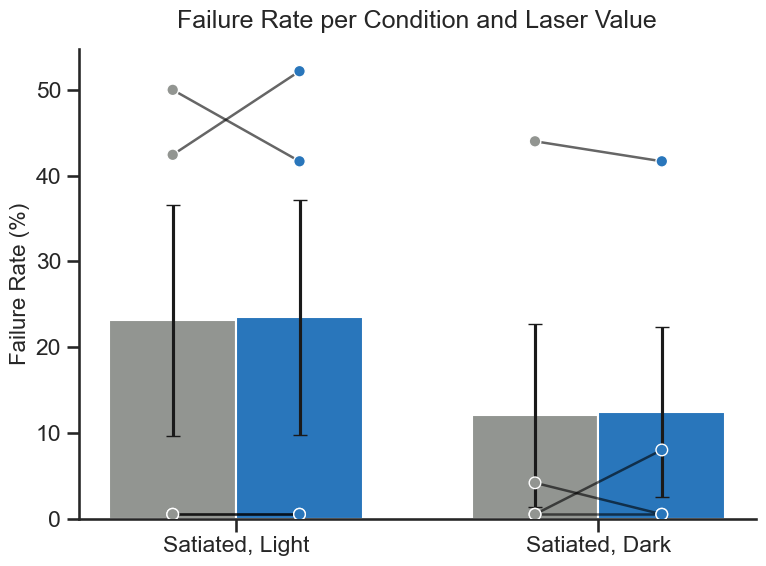

In [63]:


# === STEP 1: Extract mouse ID and clean dataframe ===
# Assumes your dataframe is named `cleaned_df`
cleaned_df["mouse"] = cleaned_df["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)

df = cleaned_df.copy()

# Ensure condition and laser_value are numeric (handles "1.0", "2.0", etc.)
df["condition"] = pd.to_numeric(df["condition"], errors="coerce")
df["laser_value"] = pd.to_numeric(df["laser_value"], errors="coerce")

# ✅ Keep only relevant conditions 1.0 and 2.0
df = df[df["condition"].isin([1.0, 2.0])]

# === STEP 2: Compute failure rate (NaN-based) ===
# Define which column represents trial success/failure (NaN = failure)
key_col = "captureT"  # change if needed, e.g., "timetoapproach"

if key_col not in df.columns:
    raise ValueError(f"Column '{key_col}' not found in dataframe. Available columns: {df.columns.tolist()}")

# Group and aggregate
failure_summary = (
    df.groupby(["mouse", "condition", "laser_value"], as_index=False)
    .agg(
        n_trials=(key_col, "size"),
        n_failures=(key_col, lambda x: x.isna().sum()),
    )
)
failure_summary["failure_rate"] = (failure_summary["n_failures"] / failure_summary["n_trials"]) * 100

# If it's still empty, warn early
if failure_summary.empty:
    raise ValueError("No valid data found after filtering. Check condition values or key_col.")

print("✅ Computed failure rates:")
print(failure_summary.head(), "\n")

# === STEP 3: Rank-sum test (Laser ON vs OFF) ===
rank_results = []
for condition, subset in failure_summary.groupby("condition"):
    group0 = subset.loc[subset["laser_value"] == 0, "failure_rate"].dropna()
    group1 = subset.loc[subset["laser_value"] == 1, "failure_rate"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        stat, pval = ranksums(group0, group1)
    else:
        stat, pval = np.nan, np.nan
    
    rank_results.append({"condition": condition, "stat": stat, "pval": pval})

rank_df = pd.DataFrame(rank_results)
print("📊 Rank-sum test results:")
print(rank_df, "\n")

# === STEP 4: Plot ===


# Example variables (adjust as needed)
# condition_positions = [0, 1]  # x-axis positions for Condition 1 and 2
# bar_width = 0.35
# offsets = [-bar_width/2, bar_width/2]  # for Laser OFF and ON
# hue_order = [0, 1]
# palette = {0: '#929591', 1: '#2976bb'}
# sns.set_style('ticks')

plt.figure(figsize=(8, 6))
# plt.grid(False)  # remove background grid

# Plot bars
for i, cond in enumerate([1.0, 2.0]):
    for j, lv in enumerate(hue_order):
        subset = failure_summary[
            (failure_summary["condition"] == cond) &
            (failure_summary["laser_value"] == lv)
        ]
        if not subset.empty:
            mean_rate = subset["failure_rate"].mean()
            se = subset["failure_rate"].sem()
            plt.bar(
                x=i + offsets[j],
                height=mean_rate,
                width=bar_width,
                color=palette[lv],
                yerr=se,
                capsize=5
            )

# Overlay per-mouse lines and points with slight y-offset for 0%
y_offset = 0.5
for mouse, subdf in failure_summary.groupby("mouse"):
    for i, cond in enumerate([1.0, 2.0]):
        mdata = subdf[subdf["condition"] == cond].sort_values("laser_value")
        if mdata.empty:
            continue
        y_vals = mdata["failure_rate"].apply(lambda y: y + y_offset if y == 0 else y)
        x_vals = np.array([i + offsets[hue_order.index(lv)] for lv in mdata["laser_value"]])
        plt.plot(x_vals, y_vals, color="black", alpha=0.6, linewidth=1.8, zorder=3)
        plt.scatter(
            x_vals,
            y_vals,
            s=70,
            c=[palette[int(lv)] for lv in mdata["laser_value"]],
            edgecolors="white",
            linewidths=1,
            zorder=4
        )

# Set x and y ticks explicitly
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
# plt.yticks(np.arange(0, 101, 10), fontsize=14)  # 0% to 100% with step of 10
plt.ylabel("Failure Rate (%)", fontsize=16)
plt.title("Failure Rate per Condition and Laser Value", fontsize=18, pad=15)




sns.despine()
plt.tight_layout()
plt.show()





✅ Computed failure rates:
    mouse  condition  laser_value  n_trials  n_failures  failure_rate
0  3180.0        1.0          0.0        12           6     50.000000
1  3180.0        1.0          1.0        12           5     41.666667
2  3180.0        2.0          0.0         4           0      0.000000
3  3180.0        2.0          1.0         4           0      0.000000
4  3181.0        1.0          0.0        24           0      0.000000 

📊 Rank-sum test results:
   condition      stat      pval
0        1.0  0.218218  0.827259
1        2.0 -0.218218  0.827259 



/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_30823/2105782373.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_df_M["mouse"] = cleaned_df_M["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)


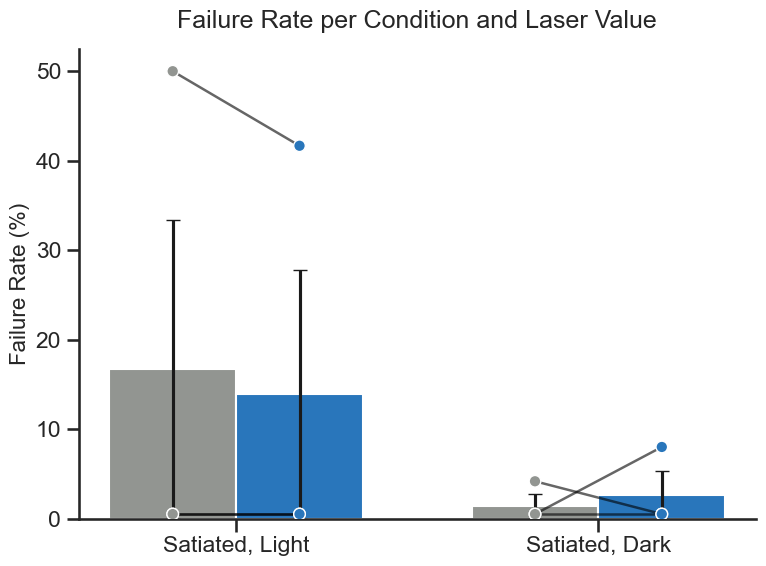

In [62]:


# === STEP 1: Extract mouse ID and clean dataframe ===
# Assumes your dataframe is named `cleaned_df`
cleaned_df_M["mouse"] = cleaned_df_M["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)

df = cleaned_df_M.copy()

# Ensure condition and laser_value are numeric (handles "1.0", "2.0", etc.)
df["condition"] = pd.to_numeric(df["condition"], errors="coerce")
df["laser_value"] = pd.to_numeric(df["laser_value"], errors="coerce")

# ✅ Keep only relevant conditions 1.0 and 2.0
df = df[df["condition"].isin([1.0, 2.0])]

# === STEP 2: Compute failure rate (NaN-based) ===
# Define which column represents trial success/failure (NaN = failure)
key_col = "captureT"  # change if needed, e.g., "timetoapproach"

if key_col not in df.columns:
    raise ValueError(f"Column '{key_col}' not found in dataframe. Available columns: {df.columns.tolist()}")

# Group and aggregate
failure_summary = (
    df.groupby(["mouse", "condition", "laser_value"], as_index=False)
    .agg(
        n_trials=(key_col, "size"),
        n_failures=(key_col, lambda x: x.isna().sum()),
    )
)
failure_summary["failure_rate"] = (failure_summary["n_failures"] / failure_summary["n_trials"]) * 100

# If it's still empty, warn early
if failure_summary.empty:
    raise ValueError("No valid data found after filtering. Check condition values or key_col.")

print("✅ Computed failure rates:")
print(failure_summary.head(), "\n")

# === STEP 3: Rank-sum test (Laser ON vs OFF) ===
rank_results = []
for condition, subset in failure_summary.groupby("condition"):
    group0 = subset.loc[subset["laser_value"] == 0, "failure_rate"].dropna()
    group1 = subset.loc[subset["laser_value"] == 1, "failure_rate"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        stat, pval = ranksums(group0, group1)
    else:
        stat, pval = np.nan, np.nan
    
    rank_results.append({"condition": condition, "stat": stat, "pval": pval})

rank_df = pd.DataFrame(rank_results)
print("📊 Rank-sum test results:")
print(rank_df, "\n")

# === STEP 4: Plot ===


# Example variables (adjust as needed)
# condition_positions = [0, 1]  # x-axis positions for Condition 1 and 2
# bar_width = 0.35
# offsets = [-bar_width/2, bar_width/2]  # for Laser OFF and ON
# hue_order = [0, 1]
# palette = {0: '#929591', 1: '#2976bb'}
# sns.set_style('ticks')

plt.figure(figsize=(8, 6))
# plt.grid(False)  # remove background grid

# Plot bars
for i, cond in enumerate([1.0, 2.0]):
    for j, lv in enumerate(hue_order):
        subset = failure_summary[
            (failure_summary["condition"] == cond) &
            (failure_summary["laser_value"] == lv)
        ]
        if not subset.empty:
            mean_rate = subset["failure_rate"].mean()
            se = subset["failure_rate"].sem()
            plt.bar(
                x=i + offsets[j],
                height=mean_rate,
                width=bar_width,
                color=palette[lv],
                yerr=se,
                capsize=5
            )

# Overlay per-mouse lines and points with slight y-offset for 0%
y_offset = 0.5
for mouse, subdf in failure_summary.groupby("mouse"):
    for i, cond in enumerate([1.0, 2.0]):
        mdata = subdf[subdf["condition"] == cond].sort_values("laser_value")
        if mdata.empty:
            continue
        y_vals = mdata["failure_rate"].apply(lambda y: y + y_offset if y == 0 else y)
        x_vals = np.array([i + offsets[hue_order.index(lv)] for lv in mdata["laser_value"]])
        plt.plot(x_vals, y_vals, color="black", alpha=0.6, linewidth=1.8, zorder=3)
        plt.scatter(
            x_vals,
            y_vals,
            s=70,
            c=[palette[int(lv)] for lv in mdata["laser_value"]],
            edgecolors="white",
            linewidths=1,
            zorder=4
        )

# Set x and y ticks explicitly
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
# plt.yticks(np.arange(0, 101, 10), fontsize=14)  # 0% to 100% with step of 10
plt.ylabel("Failure Rate (%)", fontsize=16)
plt.title("Failure Rate per Condition and Laser Value", fontsize=18, pad=15)




sns.despine()
plt.tight_layout()
plt.show()





In [43]:
print(failure_summary["condition"].unique())
print(failure_summary.head())
print(len(failure_summary))


[]
Empty DataFrame
Columns: [mouse, condition, laser_value, n_trials, n_failures, failure_rate]
Index: []
0


Rank-sum test results (mice ≠ 3179):
   condition      stat      pval
0        1.0  1.091089  0.275234
1        2.0  1.963961  0.049535



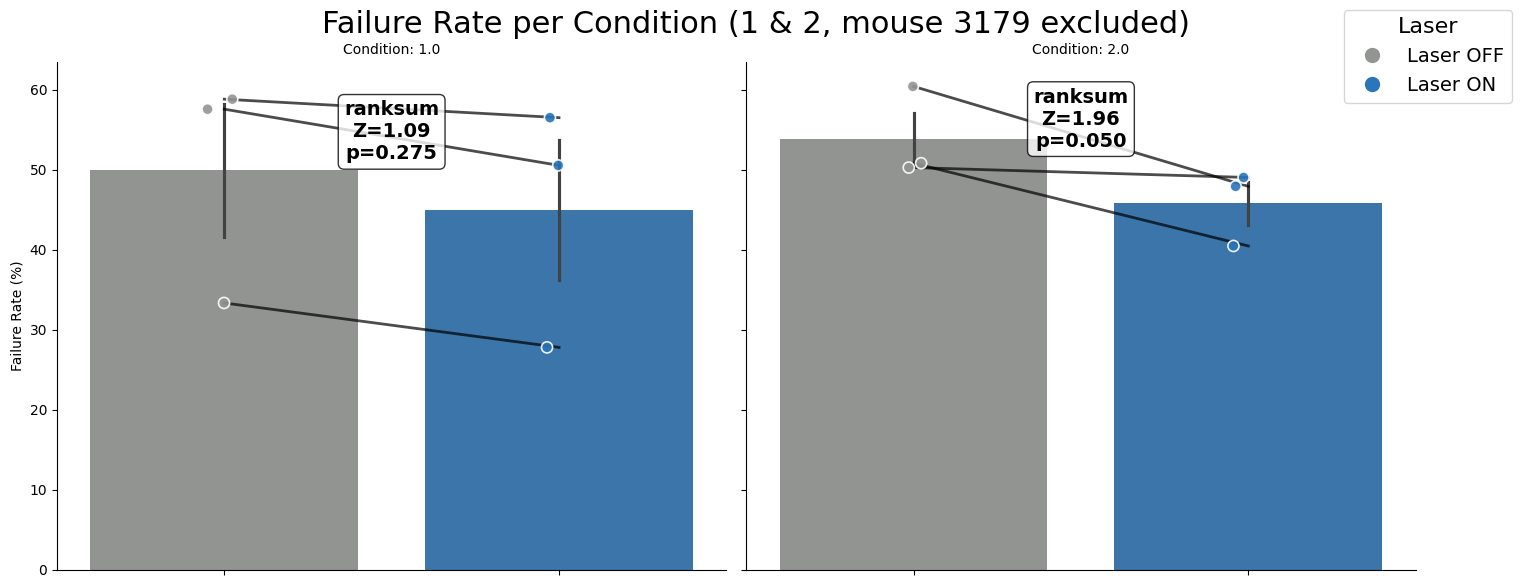

In [21]:
# import re
# import pandas as pd
# import seaborn as sns
# import matplotlib.pyplot as plt
# from scipy.stats import ranksums
# import numpy as np

# === STEP 1: Extract mouse IDs and clean dataframe ===
# Your main dataframe is 'df' with columns including:
# ['filename', 'condition', 'laser_value', 'prob_capture']

# Extract mouse number (handles "mouse-3179" or "mouse_3179")
df["mouse"] = df["filename"].str.extract(r"mouse[-_]?(\d+)").astype(float)

# Drop missing info
df_clean = df.dropna(subset=['mouse', 'condition', 'laser_value', 'prob_capture']).copy()

# ✅ Keep only conditions 1 and 2
df_clean = df_clean[df_clean["condition"].isin([1, 2])]

# ✅ Exclude mouse 3179
df_clean = df_clean[df_clean["mouse"] != 3179]

# Compute failure rate (%)
df_clean["failure_rate"] = (1 - df_clean["prob_capture"]) * 100

# Compute per-mouse mean failure rate within each condition + laser_value
failure_rates = (
    df_clean.groupby(["mouse", "condition", "laser_value"], as_index=False)
    ["failure_rate"].mean()
)

# === STEP 2: Rank-sum test per condition (laser ON vs OFF) ===
rank_results = []
for condition, subset in failure_rates.groupby("condition"):
    group0 = subset.loc[subset["laser_value"] == 0, "failure_rate"].dropna()
    group1 = subset.loc[subset["laser_value"] == 1, "failure_rate"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        stat, pval = ranksums(group0, group1)
    else:
        stat, pval = np.nan, np.nan
    
    rank_results.append({"condition": condition, "stat": stat, "pval": pval})

rank_df = pd.DataFrame(rank_results)
print("Rank-sum test results (mice ≠ 3179):")
print(rank_df)
print()

# === STEP 3: Plot ===
# sns.set(style="whitegrid", context="poster")

palette = {1: '#2976bb', 0: '#929591'}
hue_order = [0, 1]

g = sns.catplot(
    data=failure_rates,
    x='laser_value',
    y='failure_rate',
    col='condition',
    kind='bar',
    errorbar='se',
    hue='laser_value',
    hue_order=hue_order,
    palette=palette,
    height=6,       # larger subplots
    aspect=1.2
)

# Overlay per-mouse lines and points
for ax, (condition, subset) in zip(g.axes.flat, failure_rates.groupby('condition')):
    subset = subset.sort_values(['mouse', 'laser_value'])
    
    # Draw per-mouse connecting lines
    for mouse, mouse_data in subset.groupby('mouse'):
        y_vals = mouse_data['failure_rate'].replace(0, 1)
        ax.plot(
            mouse_data['laser_value'],
            y_vals,
            color='black',
            alpha=0.7,
            linewidth=2,
            zorder=3
        )

    # Overlay scatter points
    sns.stripplot(
        data=subset.assign(failure_rate_vis=subset['failure_rate'].replace(0, 1)),
        x='laser_value',
        y='failure_rate_vis',
        hue='laser_value',
        hue_order=hue_order,
        palette=palette,
        dodge=False,
        alpha=0.9,
        size=8,
        edgecolor='white',
        linewidth=1.2,
        ax=ax,
        legend=False,
        zorder=4,
        jitter=0.05
    )

    ax.set_xticklabels([])

    # Add rank-sum annotation
    cond_stat = rank_df.loc[rank_df["condition"] == condition, "stat"].values[0]
    cond_pval = rank_df.loc[rank_df["condition"] == condition, "pval"].values[0]
    ax.text(
        0.5,
        ax.get_ylim()[1] * 0.95,
        f"ranksum\nZ={cond_stat:.2f}\np={cond_pval:.3f}",
        ha='center',
        va='top',
        fontsize=14,
        fontweight='bold',
        color='black',
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8)
    )

# Beautify
g.set_axis_labels("", "Failure Rate (%)")
g.set_titles("Condition: {col_name}")
g.fig.suptitle("Failure Rate per Condition (1 & 2, mouse 3179 excluded)", y=1.03, fontsize=22)

if g._legend is not None:
    g._legend.remove()

handles = [
    plt.Line2D([0], [0], color=palette[0], marker='o', linestyle='', markersize=10),
    plt.Line2D([0], [0], color=palette[1], marker='o', linestyle='', markersize=10)
]
labels = ["Laser OFF", "Laser ON"]
g.fig.legend(handles, labels, title="Laser", loc='upper right', fontsize=14, title_fontsize=16)

# plt.tight_layout()
# plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_failurerate_M_wstats.pdf')

plt.show()


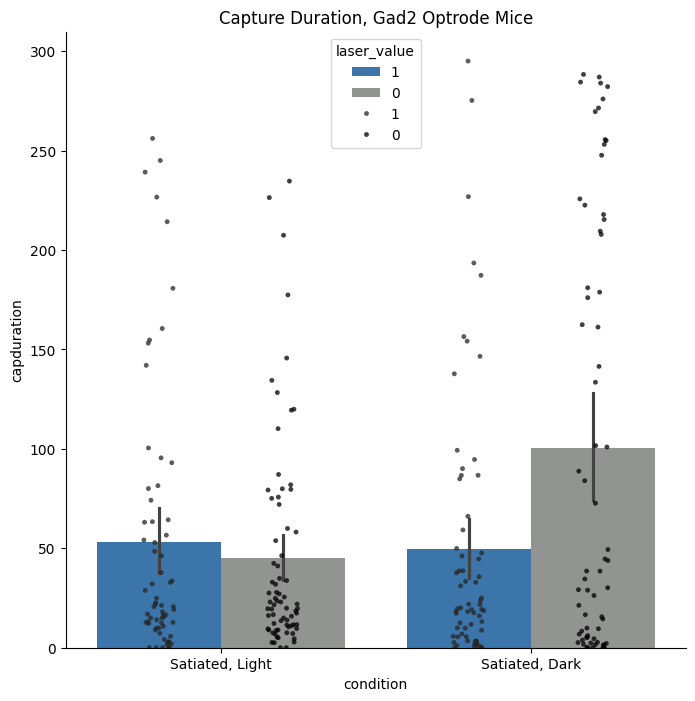

In [16]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=cleaned_df, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, Gad2 Optrode Mice')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meancapduration.pdf')

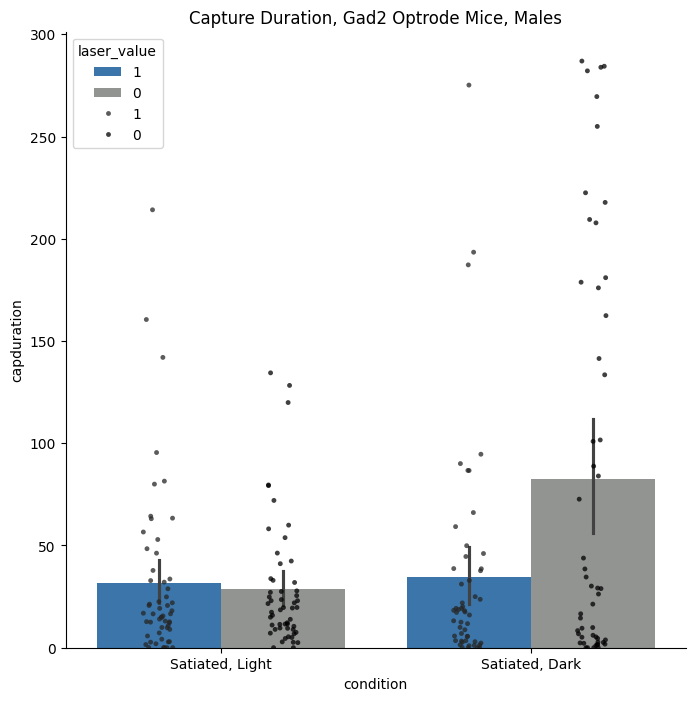

In [22]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df_M, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=cleaned_df_M, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, Gad2 Optrode Mice, Males')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meancapduration_M.pdf')

In [28]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df.dropna(subset=["capduration", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["capduration"].dropna()
    group1 = group[group["laser_value"] == 1]["capduration"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               73               66  -0.080140  0.936126
1       2.0               66               66   1.868246  0.061728


In [30]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df_M.dropna(subset=["capduration", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["capduration"].dropna()
    group1 = group[group["laser_value"] == 1]["capduration"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               54               55   0.230303  0.817856
1       2.0               52               52   1.570037  0.116407


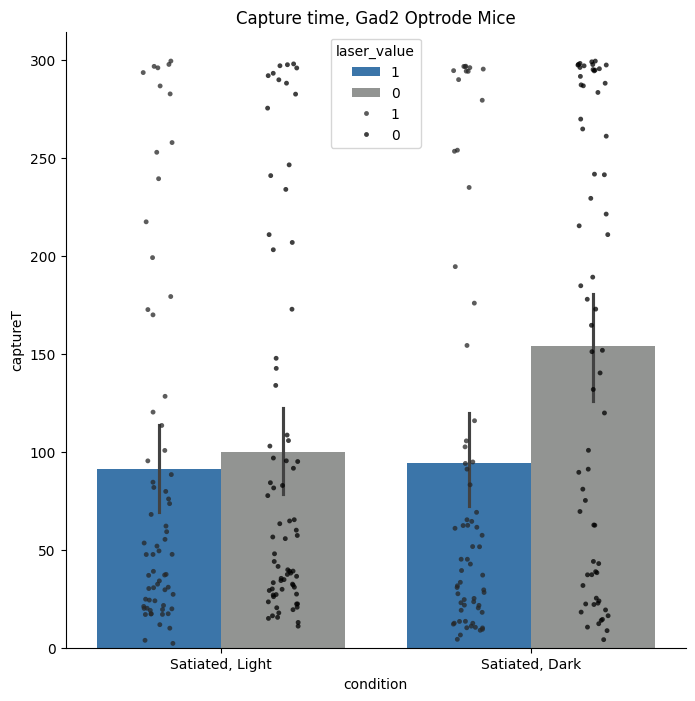

In [17]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=cleaned_df, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture time, Gad2 Optrode Mice')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meancaptime.pdf')

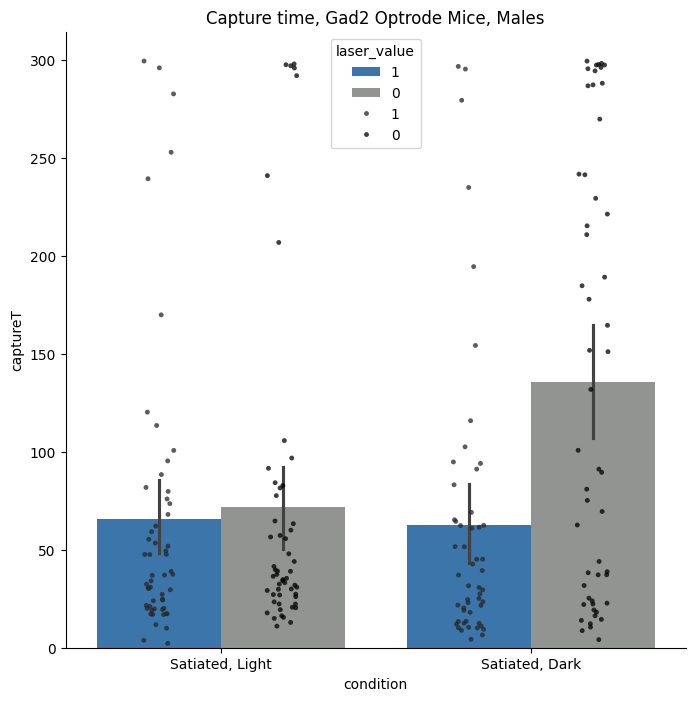

In [6]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df_M, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=cleaned_df_M, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture time, Gad2 Optrode Mice, Males')
# plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meancaptime_M.pdf')

In [7]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df.dropna(subset=["captureT", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["captureT"].dropna()
    group1 = group[group["laser_value"] == 1]["captureT"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               73               66   0.898406  0.368969
1       2.0               66               66   3.049269  0.002294


In [8]:

from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df_M.dropna(subset=["captureT", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["captureT"].dropna()
    group1 = group[group["laser_value"] == 1]["captureT"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               54               55   0.533333  0.593803
1       2.0               52               52   3.270097  0.001075


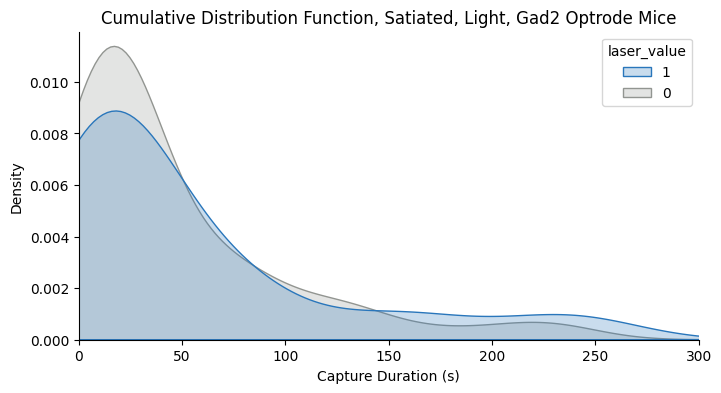

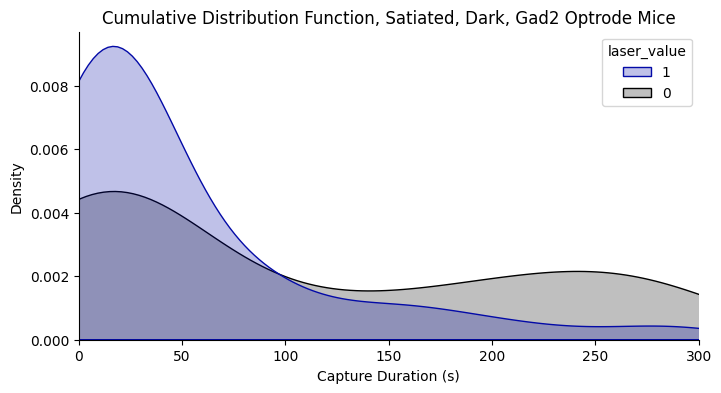

In [18]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='1.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcapduration_light.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='2.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 300)
# plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcapduration_dark.pdf')

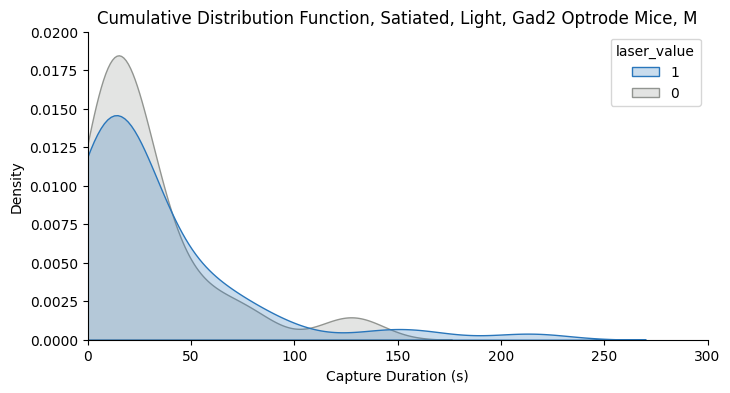

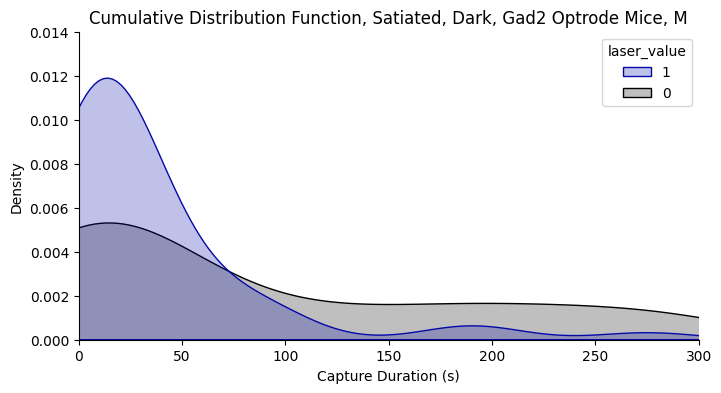

In [17]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='1.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice, M')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
plt.ylim(0, 0.020)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcapduration_light_M.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='2.0')], x='capduration', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Duration (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice, M')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(-0, 300)
plt.ylim(0, 0.014)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcapduration_dark_M.pdf')

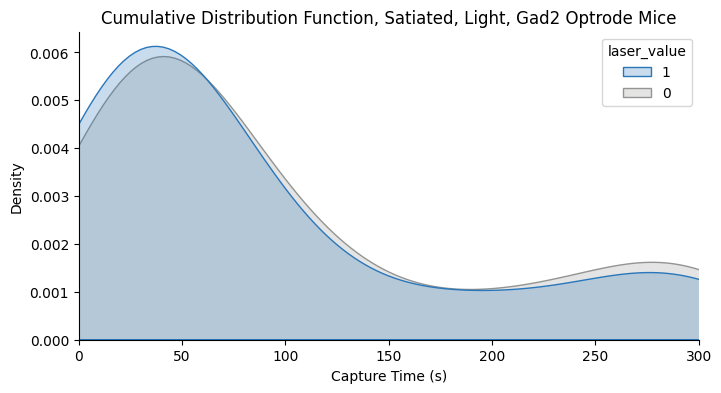

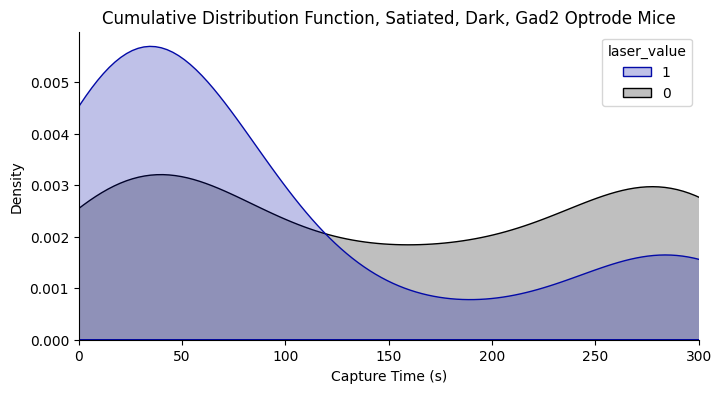

In [20]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='1.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcaptime_light.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='2.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 300)
# plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcaptime_dark.pdf')


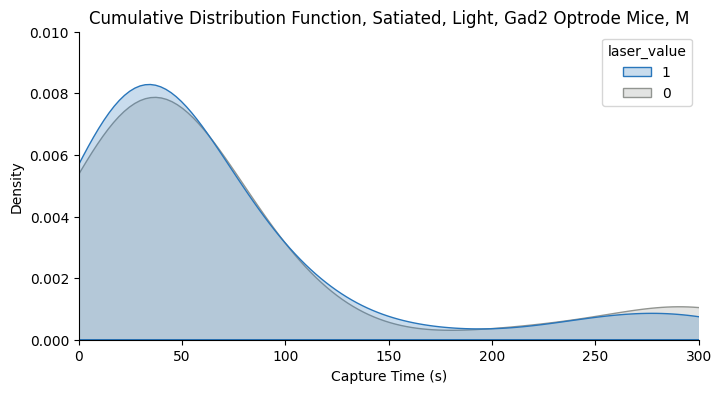

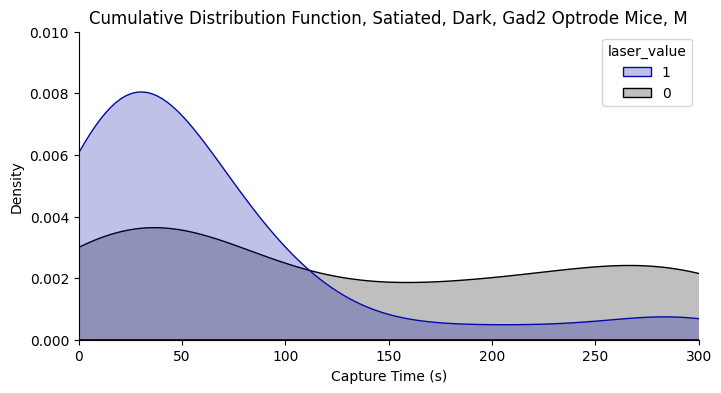

In [20]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='1.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice, M')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 300)
plt.ylim(0, 0.010)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcaptime_light_M.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='2.0')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice, M')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 300)
plt.ylim(0, 0.010)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distcaptime_dark_M.pdf')


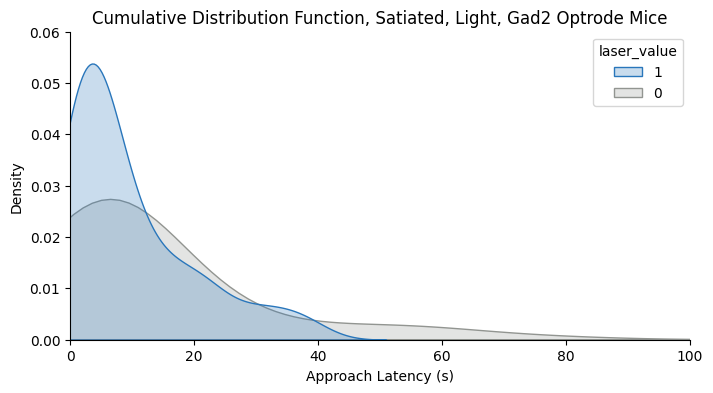

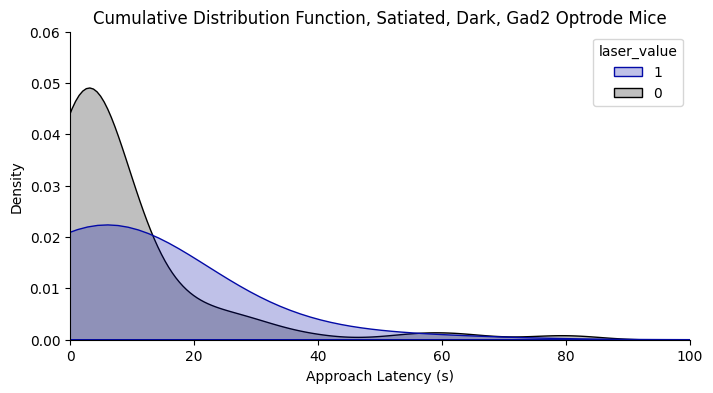

In [5]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='1.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 100)
plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distapproachlatency_light.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='2.0')], x='timetoapproach', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Approach Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 100)
plt.ylim(0, 0.06)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distapproachlatency_dark.pdf')

In [14]:

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = df.dropna(subset=["timetoapproach", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["timetoapproach"].dropna()
    group1 = group[group["laser_value"] == 1]["timetoapproach"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


   condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0        0.0               71                1        NaN       NaN
1        1.0               93               83   1.157296  0.247151
2        2.0               78               78  -1.566637  0.117199


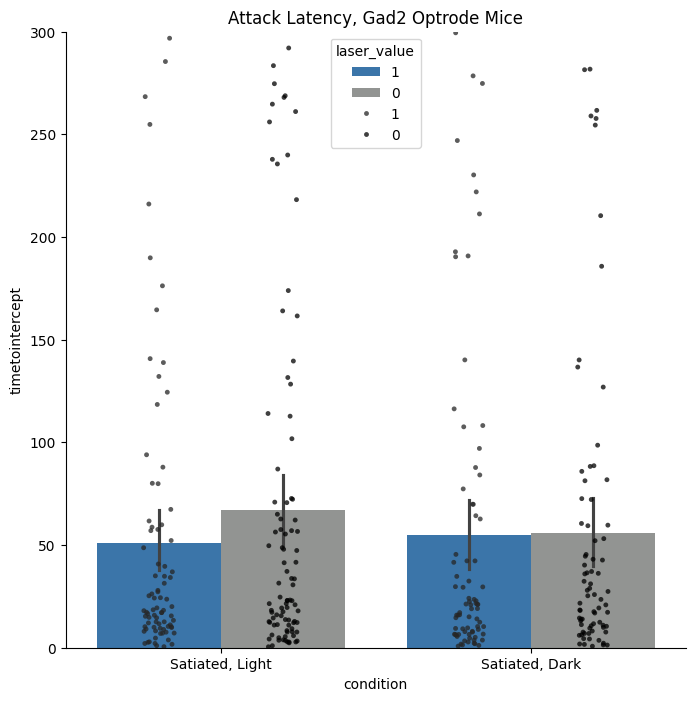

In [9]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df, x='condition', y='timetointercept', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='timetointercept', hue='laser_value',dodge=True, data=cleaned_df, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Attack Latency, Gad2 Optrode Mice')
plt.ylim(0,300)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meanattacklatency.pdf')

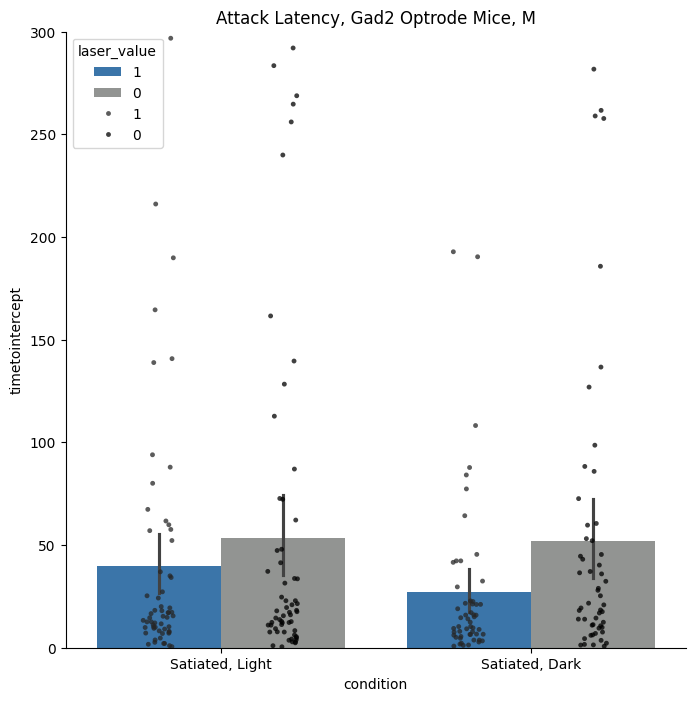

In [9]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_df_M, x='condition', y='timetointercept', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='timetointercept', hue='laser_value',dodge=True, data=cleaned_df_M, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Attack Latency, Gad2 Optrode Mice, M')
plt.ylim(0,300)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_meanattacklatency_M.pdf')

In [10]:

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df.dropna(subset=["timetointercept", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["timetointercept"].dropna()
    group1 = group[group["laser_value"] == 1]["timetointercept"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)


  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               92               82   1.049180  0.294095
1       2.0               77               78   0.830278  0.406382


In [11]:
# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_df_M.dropna(subset=["timetointercept", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["timetointercept"].dropna()
    group1 = group[group["laser_value"] == 1]["timetointercept"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)

  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0       1.0               59               59   0.562447  0.573812
1       2.0               53               54   2.305397  0.021144


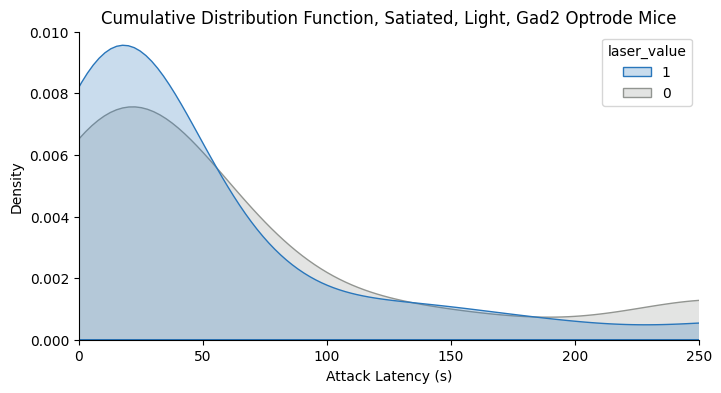

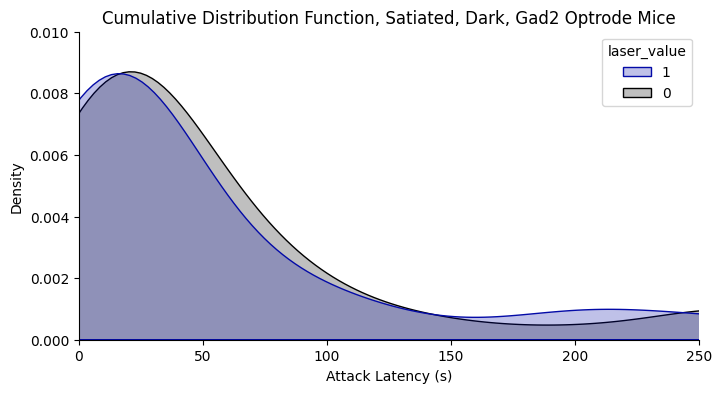

In [ ]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='1.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 250)
plt.ylim(0, 0.010)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distattacklatency_light.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df.iloc[np.where(cleaned_df['condition']=='2.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 250)
plt.ylim(0, 0.010)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distattacklatency_dark.pdf')


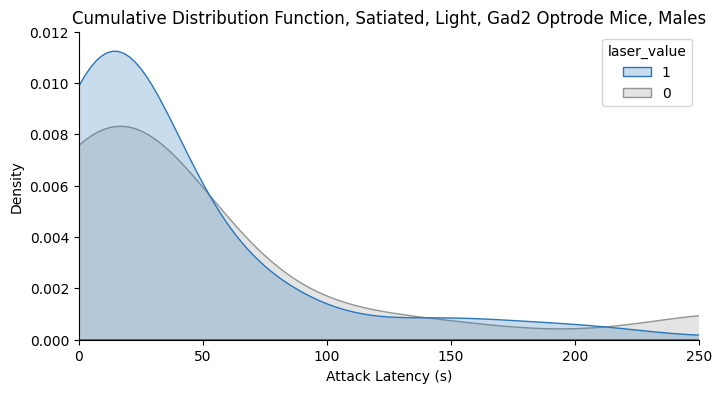

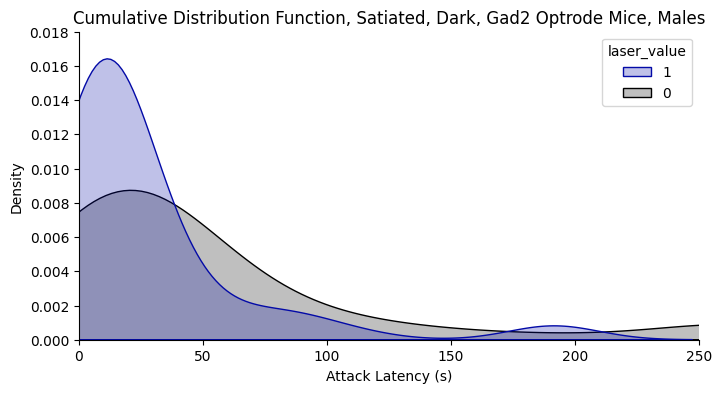

In [14]:
darkpalette=['#030aa7','#000000']
fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='1.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, Gad2 Optrode Mice, Males')
# plt.xticks(np.arange(0, 175,25))
plt.xlim(0, 250)
plt.ylim(0, 0.012)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distattacklatency_light_M.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_df_M.iloc[np.where(cleaned_df_M['condition']=='2.0')], x='timetointercept', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
plt.xlabel('Attack Latency (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, Gad2 Optrode Mice, Males')
# plt.xticks(np.arange(-50, 325,25))
plt.xlim(0, 250)
plt.ylim(0, 0.018)
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_distattacklatency_dark_M.pdf')


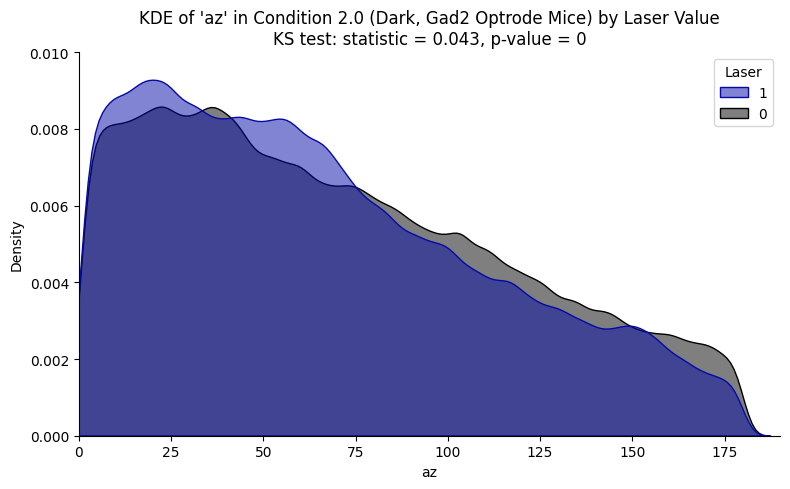

In [40]:

from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
plt.ylim(0,0.010)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_az_dark.pdf')

plt.show()


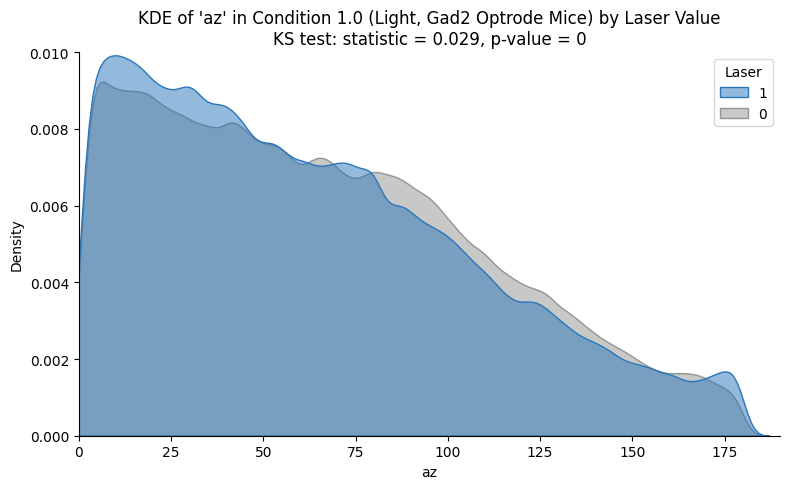

In [41]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,190)
plt.ylim(0,0.010)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_az_light.pdf')

plt.show()


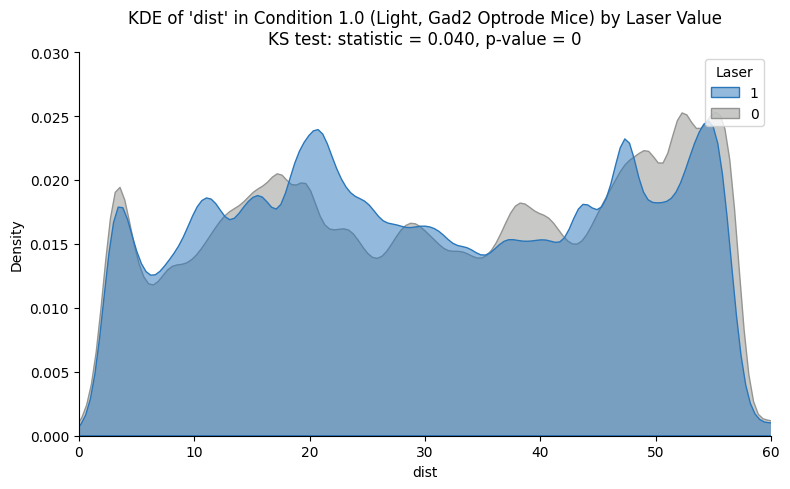

In [50]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
plt.ylim(0,0.030)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_range_light.pdf')

plt.show()


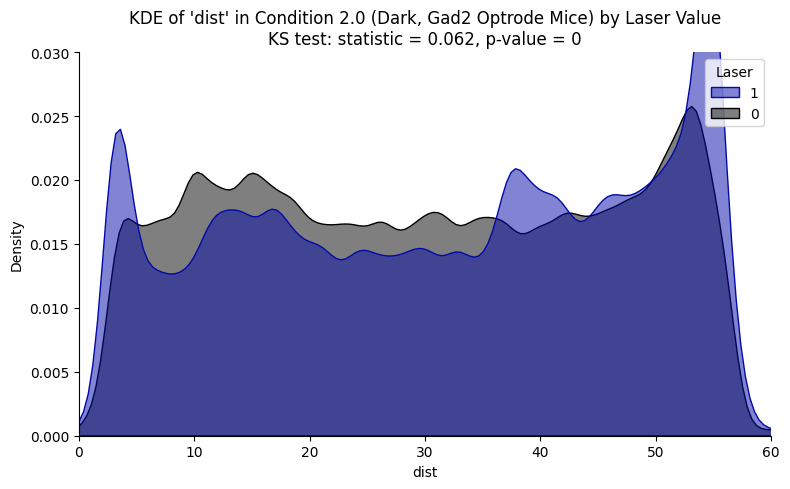

In [51]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
plt.ylim(0,0.030)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_range_dark.pdf')

plt.show()


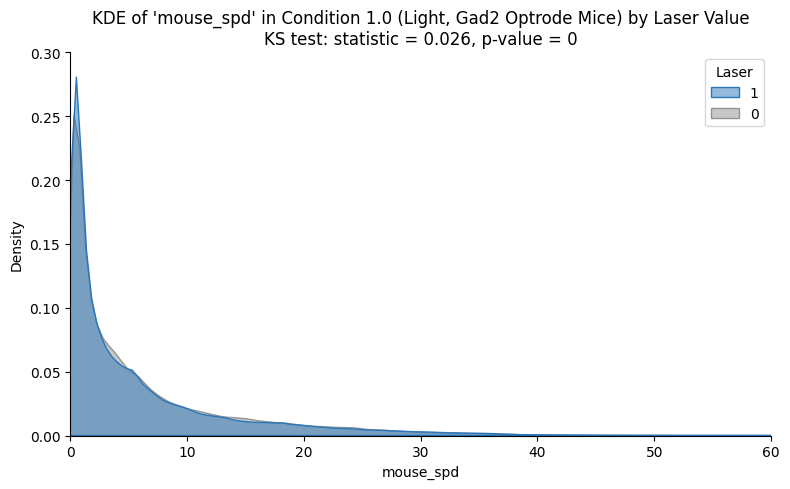

In [45]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
plt.ylim(0,0.30)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_spd_light.pdf')

plt.show()


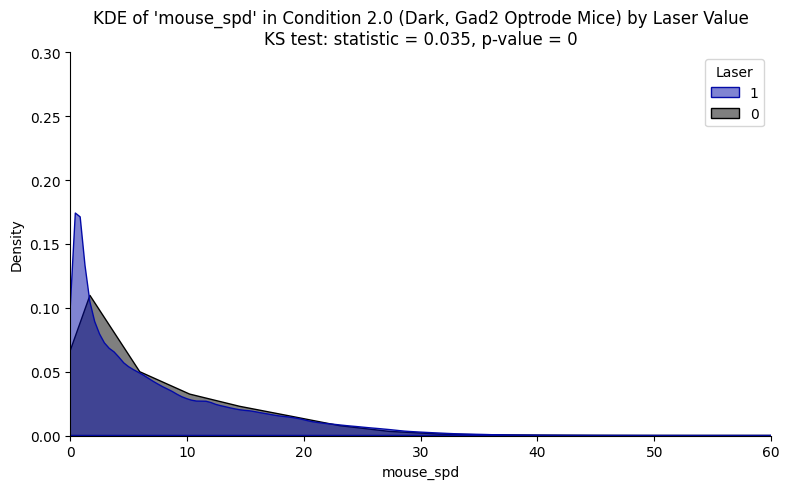

In [47]:

# from scipy.stats import ks_2samp

# Settings
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2.0'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_df.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, Gad2 Optrode Mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xlim(0,60)
plt.ylim(0,0.30)
plt.tight_layout()
sns.despine()
plt.savefig('/Users/mollyshallow/Desktop/WehrLab/Conferences/optrode_spd_dark.pdf')

plt.show()


### look at the total distance and prey capture distance traveled across the whole trial

In [38]:
def total_distance_from_xy_array(xy_array):
    if xy_array.shape[0] != 2:
        raise ValueError("Input should have shape (2, N), with first row x and second row y")

    # Reshape to (N, 2) where each row is [x, y]
    positions = xy_array.T  # Now shape is (N, 2)

    # Remove NaNs (in case there are dropped frames)
    positions = positions[~np.isnan(positions).any(axis=1)]

    # Compute total distance
    diffs = np.diff(positions, axis=0)
    step_distances = np.linalg.norm(diffs, axis=1)
    return np.sum(step_distances)

from scipy.signal import savgol_filter

def smooth_xy_array(xy_array, window_length=11, polyorder=2):
    """
    Smooths a 2xN array of x and y positions using Savitzky-Golay filter.
    - window_length must be odd and >= polyorder + 2
    """
    if xy_array.shape[0] != 2:
        raise ValueError("Input must be a 2xN array of x and y coordinates.")

    # Handle short arrays
    if xy_array.shape[1] < window_length:
        return xy_array  # Not enough data to smooth

    smoothed_x = savgol_filter(xy_array[0], window_length, polyorder)
    smoothed_y = savgol_filter(xy_array[1], window_length, polyorder)

    return np.vstack([smoothed_x, smoothed_y])


from scipy.stats import mannwhitneyu

def plot_distance_distributions_by_condition(df):
    conditions = sorted(df['condition'].unique())
    distance_columns = [
        ('mouse_total_distance', 'Total Distance'),
        ('preycap_distance_traveled', 'Prey Capture Distance')
    ]

    for distance_column, title_label in distance_columns:
        for cond in conditions:
            plt.figure(figsize=(8, 6))
            subset = df[df['condition'] == cond]

            group_stats = {}
            for laser_val, color, label in zip([0, 1], ['#929591', '#2976bb'], ['Laser OFF', 'Laser ON']):
                laser_subset = subset[subset['laser_value'] == laser_val]
                valid_data = laser_subset[distance_column].dropna()

                if len(valid_data) > 1:
                    sns.kdeplot(
                        x=valid_data,
                        fill=True,
                        alpha=0.5,
                        linewidth=2,
                        label=label,
                        color=color
                    )
                    mean = valid_data.mean()
                    std = valid_data.std()

                    # Add vertical mean line
                    plt.axvline(mean, color=color, linestyle='--', linewidth=1.5)

                    # Store stats for p-value test
                    group_stats[laser_val] = valid_data

                    # Add text annotation
                    plt.text(
                        mean,
                        plt.ylim()[1]*0.9 if laser_val == 0 else plt.ylim()[1]*0.8,
                        f"Mean = {mean:.1f} ± {std:.1f}",
                        color=color,
                        ha='center',
                        fontsize=10,
                        bbox=dict(facecolor='white', edgecolor=color, alpha=0.6)
                    )
                else:
                    print(f"⚠️ Not enough valid data for condition {cond}, laser {laser_val}, distance: {distance_column} — skipping KDE")

            # Optional: statistical test between laser=0 and laser=1
            if 0 in group_stats and 1 in group_stats:
                stat, pval = mannwhitneyu(group_stats[0], group_stats[1], alternative='two-sided')
                plt.text(
                    0.95, 0.95,
                    f"Mann-Whitney U p = {pval:.3f}",
                    transform=plt.gca().transAxes,
                    ha='right',
                    va='bottom',
                    fontsize=11,
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='black')
                )

            plt.title(f"{title_label} — Condition {cond}")
            plt.xlabel(f"{title_label} (units)")
            plt.ylabel("Density")
            plt.xlim(0,2500)
            plt.legend(loc='lower right')
            plt.tight_layout()
            sns.despine()
            plt.show()


        

In [39]:
FPS = 200
max_frames = int(125 * FPS)

results = []
cols_to_keep = ['filename', 'condition', 'laser_value', 'captureT', 'cricketdrop', 'captureframe']

for idx, row in cleaned_df[cols_to_keep].iterrows():
    filename = row['filename']
    capture_time = row['captureT']
    drop_frame = row['cricketdrop']
    capture_frame = row['captureframe']

    try:
        # Extract tracking points
        mouse_xy, cricket_p, cricket_xy, rear_xy, lear_xy, spine_xy, cricket_front, cricket_back = preycap.extract_points(
            filename, ['Rear', 'Lear', 'anteriorC', 'posteriorC', 'spine']
        )

        # Limit to first 125s if needed
        if pd.isna(capture_time) or capture_time > 125:
            mouse_xy = mouse_xy[:, :max_frames]

        # Smooth full trajectory
        smoothed_mouse_xy = smooth_xy_array(mouse_xy)

        # Total distance across all time
        total_mouse_distance = total_distance_from_xy_array(smoothed_mouse_xy)

        # --- Prey capture distance ---
        preycap_distance = np.nan  # default if drop/capture info is missing

        if pd.notna(drop_frame) and pd.notna(capture_frame):
            drop_frame = int(drop_frame)
            capture_frame = int(capture_frame)

            if 0 <= drop_frame < capture_frame <= mouse_xy.shape[1]:
                segment = mouse_xy[:, drop_frame:capture_frame]
                segment_smoothed = smooth_xy_array(segment)
                preycap_distance = total_distance_from_xy_array(segment_smoothed)

        # Store results
        result_row = {
            'filename': filename,
            'condition': row['condition'],
            'laser_value': row['laser_value'],
            'captureT': capture_time,
            'mouse_total_distance': total_mouse_distance,
            'preycap_distance_traveled': preycap_distance
        }
        results.append(result_row)

    except Exception as e:
        print(f"⚠️ Failed on {filename}: {e}")
        continue

# Final DataFrame
distance_df = pd.DataFrame(results)
print(distance_df.head())


                                            filename condition  laser_value  \
0  /Volumes/Projects/PreyCapture/ZI_A1Activation/...       1.0          0.0   
1  /Volumes/Projects/PreyCapture/ZI_A1Activation/...       1.0          1.0   
2  /Volumes/Projects/PreyCapture/ZI_A1Activation/...       1.0          0.0   
3  /Volumes/Projects/PreyCapture/ZI_A1Activation/...       1.0          1.0   
4  /Volumes/Projects/PreyCapture/ZI_A1Activation/...       1.0          0.0   

   captureT  mouse_total_distance  preycap_distance_traveled  
0       NaN            667.037943                        NaN  
1       NaN            476.732760                        NaN  
2       NaN            275.694288                        NaN  
3    217.47            577.361951                        NaN  
4    288.27            576.849780                        NaN  


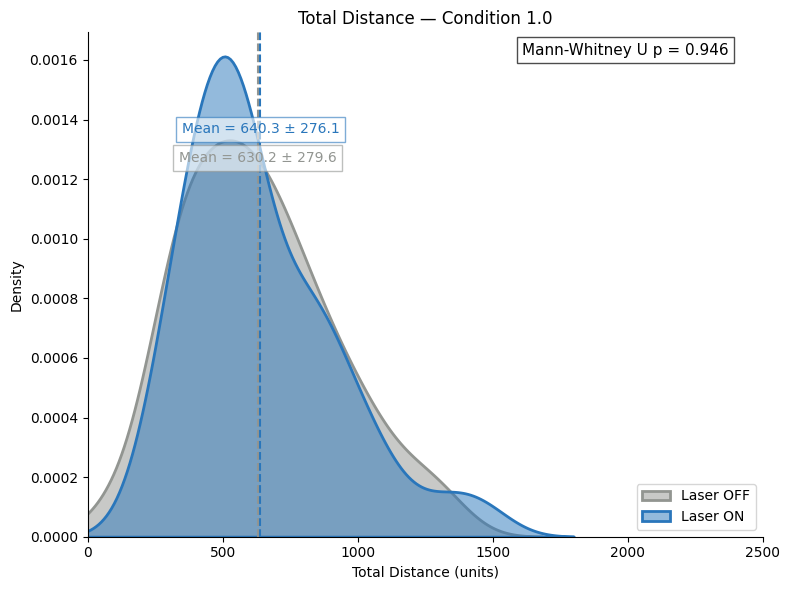

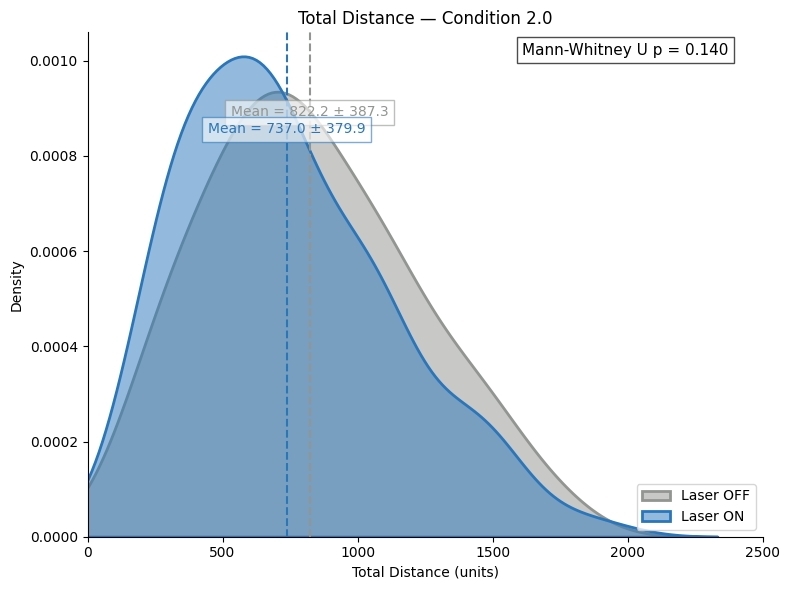

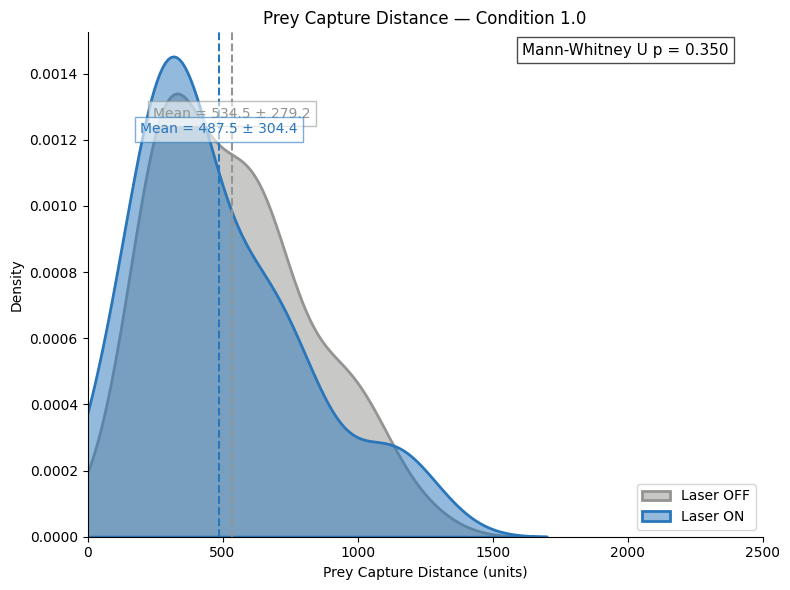

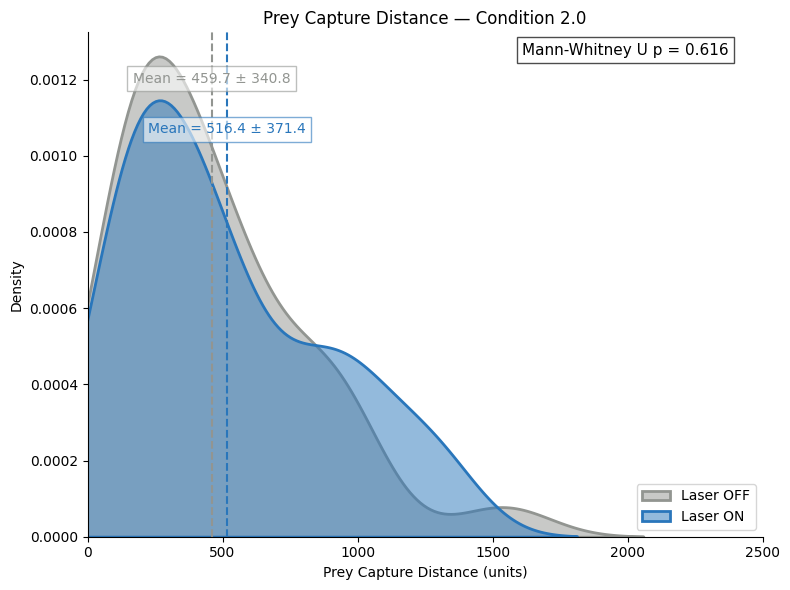

In [48]:
plot_distance_distributions_by_condition(distance_df)